# Homework 3– From an MD Trajectory to a Defensible Diffusion Coefficient

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
import numpy as np
import matplotlib.pyplot as plt


def initialize_lattice(n_particles, box_length):
    """Place particles on a square lattice."""
    n_side = int(np.ceil(np.sqrt(n_particles)))
    spacing = box_length / n_side
    coordinates = []

    for iy in range(n_side):
        for ix in range(n_side):
            if len(coordinates) >= n_particles:
                break
            coordinates.append([(ix + 0.5) * spacing,
                                (iy + 0.5) * spacing])
        if len(coordinates) >= n_particles:
            break

    return np.array(coordinates, dtype=float)


def lj_forces(positions_wrapped, box_length):
    """Return Lennard-Jones forces and potential energy in reduced units.

    This small educational system evaluates all particle pairs. Periodic
    boundaries are handled with the minimum-image convention.
    """
    r = positions_wrapped

    # Pair displacement r_i - r_j
    dr = r[:, None, :] - r[None, :, :]
    dr -= box_length * np.rint(dr / box_length)

    r2 = np.sum(dr**2, axis=2)
    np.fill_diagonal(r2, np.inf)

    inv_r2 = 1.0 / r2
    inv_r6 = inv_r2**3

    # F_ij = 24 [2 r^-14 - r^-8] r_ij
    prefactor = 24.0 * inv_r2 * (2.0 * inv_r6**2 - inv_r6)
    prefactor[np.isinf(r2)] = 0.0
    forces = np.sum(prefactor[:, :, None] * dr, axis=1)

    # Pair potential; factor 1/2 removes double counting
    pair_u = 4.0 * (inv_r6**2 - inv_r6)
    np.fill_diagonal(pair_u, 0.0)
    potential_energy = 0.5 * np.sum(pair_u)

    return forces, potential_energy


def instantaneous_temperature(velocities):
    """Return the instantaneous reduced temperature and kinetic energy."""
    kinetic_energy = 0.5 * np.sum(velocities**2)
    degrees_of_freedom = velocities.size
    temperature = 2.0 * kinetic_energy / degrees_of_freedom
    return temperature, kinetic_energy


def run_lj_md(
    ensemble='NVE',
    target_temperature=1.0,
    initial_temperature=0.5,
    dt=0.005,
    total_time=60.0,
    n_particles=36,
    density=0.65,
    sample_dt=0.05,
    seed=504,
    collision_rate=1.0,
):
    """Run a small 2D Lennard-Jones simulation with velocity Verlet.

    NVE: ordinary conservative velocity-Verlet dynamics.
    NVT: the same dynamics plus a simple Andersen thermostat. Each particle
         has a small probability collision_rate*dt of being reassigned a
         velocity drawn from the target thermal distribution.

    The thermostat implementation is supplied for this exercise; students are
    not expected to derive or modify it.
    """
    ensemble = ensemble.upper()
    if ensemble not in {'NVE', 'NVT'}:
        raise ValueError("ensemble must be 'NVE' or 'NVT'")

    box_length = np.sqrt(n_particles / density)
    positions = initialize_lattice(n_particles, box_length)
    positions_unwrapped = positions.copy()

    rng = np.random.default_rng(seed)

    velocities = rng.normal(size=(n_particles, 2))
    velocities -= velocities.mean(axis=0)

    current_temperature, _ = instantaneous_temperature(velocities)
    velocities *= np.sqrt(initial_temperature / current_temperature)

    forces, potential_energy = lj_forces(positions, box_length)

    n_steps = int(round(total_time / dt))
    sample_every = max(1, int(round(sample_dt / dt)))

    times = []
    temperatures = []
    potential_per_particle = []
    kinetic_per_particle = []
    total_per_particle = []
    trajectory = []

    for step in range(n_steps + 1):
        if step % sample_every == 0:
            temperature, kinetic_energy = instantaneous_temperature(velocities)
            times.append(step * dt)
            temperatures.append(temperature)
            potential_per_particle.append(potential_energy / n_particles)
            kinetic_per_particle.append(kinetic_energy / n_particles)
            total_per_particle.append((kinetic_energy + potential_energy) / n_particles)
            trajectory.append(positions_unwrapped.copy())

        if step == n_steps:
            break

        # Velocity-Verlet integration
        velocities += 0.5 * dt * forces
        positions_unwrapped += dt * velocities
        positions = np.mod(positions_unwrapped, box_length)

        new_forces, new_potential_energy = lj_forces(positions, box_length)
        velocities += 0.5 * dt * new_forces

        # Simple Andersen thermostat for NVT
        if ensemble == 'NVT':
            collisions = rng.random(n_particles) < collision_rate * dt
            n_collisions = int(collisions.sum())
            if n_collisions:
                velocities[collisions] = rng.normal(
                    scale=np.sqrt(target_temperature),
                    size=(n_collisions, 2),
                )

        forces = new_forces
        potential_energy = new_potential_energy

    return {
        'ensemble': ensemble,
        'time': np.array(times),
        'temperature': np.array(temperatures),
        'potential_per_particle': np.array(potential_per_particle),
        'kinetic_per_particle': np.array(kinetic_per_particle),
        'total_per_particle': np.array(total_per_particle),
        'trajectory': np.array(trajectory),
        'box_length': box_length,
    }


def normalized_autocorrelation(values, max_lag=None):
    """Normalized autocorrelation C(k) of one scalar observable time series."""
    x = np.asarray(values, dtype=float)
    x = x - x.mean()

    if max_lag is None:
        max_lag = len(x) - 1

    corr = np.correlate(x, x, mode='full')[len(x)-1:]
    normalization = np.arange(len(x), 0, -1)
    corr = corr / normalization
    corr = corr / corr[0]
    return corr[:max_lag + 1]


def block_means(values, n_blocks=10):
    """Split a time series into equal contiguous blocks and return block means."""
    values = np.asarray(values, dtype=float)
    n_per_block = len(values) // n_blocks
    trimmed = values[:n_per_block * n_blocks]
    return trimmed.reshape(n_blocks, n_per_block).mean(axis=1)


## Part 1– Independent production trajectories

a. Why are different initial velocities / random seeds useful when checking convergence?

Different random seeds generate different initial velocities, producing independent trajectories. Comparing their results helps assess whether the estimated equilibrium properties are reproducible and sufficiently sampled rather than dependent on one particular trajectory.

b. Should the two trajectories be identical? Should estimates of the same equilibrium transport property be reasonably consistent if sampling is adequate?

No, the trajectories should not be identical because they start with different velocities. However, if sampling is adequate, both should produce reasonably consistent estimates of the same equilibrium transport property, such as the diffusion coefficient.

In [10]:
replica1 = run_lj_md(
    ensemble='NVE',
    initial_temperature=1.0,
    seed=504
)

replica2 = run_lj_md(
    ensemble='NVE',
    initial_temperature=1.0,
    seed=509
)

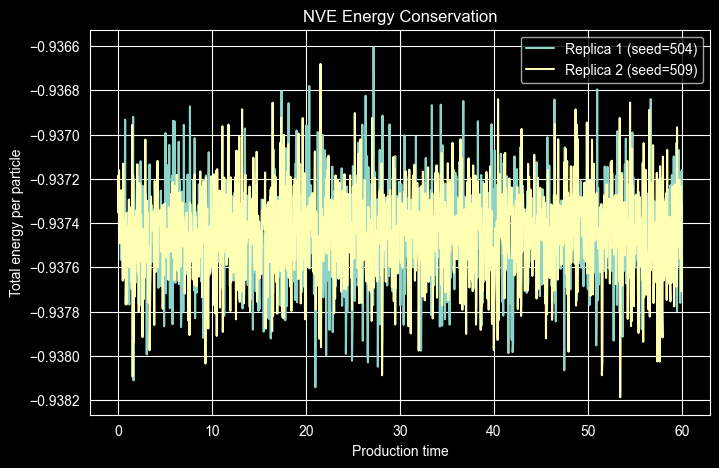

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(replica1['time'],
         replica1['total_per_particle'],
         label='Replica 1 (seed=504)')

plt.plot(replica2['time'],
         replica2['total_per_particle'],
         label='Replica 2 (seed=509)')

plt.xlabel('Production time')
plt.ylabel('Total energy per particle')
plt.title('NVE Energy Conservation')
plt.legend()
plt.grid(True)
plt.show()

Comment on whether either
production trajectory shows obvious systematic energy drift, and explain why this check should be
made before analyzing diffusion

The total energy per particle remains approximately constant throughout both NVE trajectories, with small numerical fluctuations and no obvious systematic drift. This indicates reasonable energy conservation during the simulations. Checking energy conservation before analyzing diffusion is important because significant energy drift may indicate numerical integration errors or unstable dynamics, which could make the calculated diffusion coefficient unreliable.

## Part 2– Wrapped versus unwrapped motion

In [12]:
unwrapped = replica1['trajectory']
L = replica1["box_length"]

wrapped = np.mod(unwrapped, L)

In [17]:
max_lag = 300

msd_wrapped = []
msd_unwrapped = []

for lag in range(max_lag+1):
    if lag ==0:
        msd_wrapped.append(0)
        msd_unwrapped.append(0)

    else:
        dr_w = wrapped[lag:] - wrapped[:-lag]
        dr_u = unwrapped[lag:] - unwrapped[:-lag]

        msd_wrapped.append(np.mean(np.sum(dr_w**2, axis=2)))
        msd_unwrapped.append(np.mean(np.sum(dr_u**2, axis=2)))

msd_wrapped = np.array(msd_wrapped)
msd_unwrapped = np.array(msd_unwrapped)

lag_times = replica1['time'][:max_lag + 1] - replica1['time'][0]

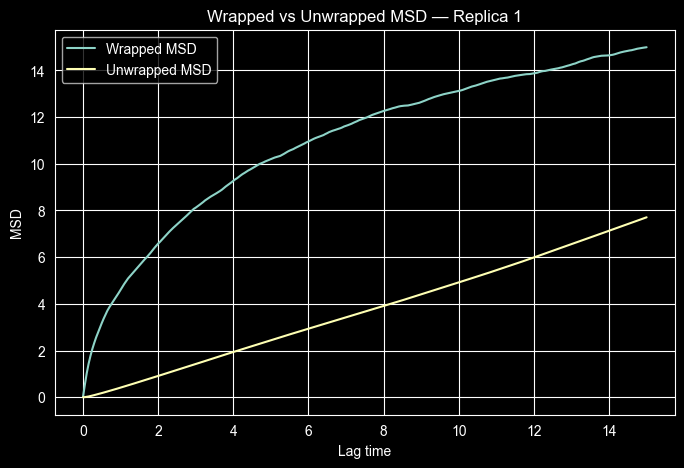

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(lag_times, msd_wrapped, label='Wrapped MSD')
plt.plot(lag_times, msd_unwrapped, label='Unwrapped MSD')

plt.xlabel('Lag time')
plt.ylabel('MSD')
plt.title('Wrapped vs Unwrapped MSD — Replica 1')
plt.legend()
plt.grid(True)
plt.show()

a. Why is an MSD calculated directly from wrapped coordinates incorrect for long-time diffusion analysis?

Wrapped coordinates introduce artificial jumps when particles cross periodic boundaries. These jumps do not represent their actual continuous motion, so the calculated MSD becomes incorrect for long-time diffusion analysis.

b. Which coordinate representation should be used to preserve physical translational displacement?

Unwrapped coordinates should be used because they preserve the continuous displacement of particles across periodic boundaries.

## Part 3– Obtain the diffusion coefficient

In [19]:
unwrapped2 = replica2['trajectory']

msd_unwrapped2 = []

for lag in range(max_lag + 1):
    if lag == 0:
        msd_unwrapped2.append(0.0)
    else:
        dr = unwrapped2[lag:] - unwrapped2[:-lag]
        msd_unwrapped2.append(np.mean(np.sum(dr**2, axis=2)))

msd_unwrapped2 = np.array(msd_unwrapped2)

In [20]:
fit_mask = (lag_times >= 2) & (lag_times <= 8)

slope1, intercept1 = np.polyfit(
    lag_times[fit_mask],
    msd_unwrapped[fit_mask],
    1
)

slope2, intercept2 = np.polyfit(
    lag_times[fit_mask],
    msd_unwrapped2[fit_mask],
    1
)

D1 = slope1 / 4
D2 = slope2 / 4

print("D1 =", D1)
print("D2 =", D2)

D1 = 0.12469998015222147
D2 = 0.14768970181419902


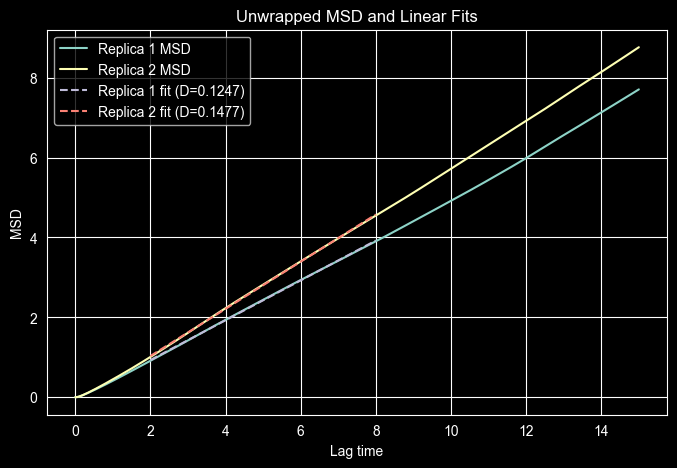

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(lag_times, msd_unwrapped,
         label='Replica 1 MSD')

plt.plot(lag_times, msd_unwrapped2,
         label='Replica 2 MSD')

plt.plot(lag_times[fit_mask],
         slope1 * lag_times[fit_mask] + intercept1,
         '--', label=f'Replica 1 fit (D={D1:.4f})')

plt.plot(lag_times[fit_mask],
         slope2 * lag_times[fit_mask] + intercept2,
         '--', label=f'Replica 2 fit (D={D2:.4f})')

plt.xlabel('Lag time')
plt.ylabel('MSD')
plt.title('Unwrapped MSD and Linear Fits')
plt.legend()
plt.grid(True)
plt.show()

a. Why is D obtained from the slope rather than from a single displacement value?

The diffusion coefficient describes the average rate at which the mean squared displacement increases with time. Using the slope of the MSD curve provides a more reliable estimate than using a single displacement value, which may be affected by statistical fluctuations.

b. Why is a specified fitting interval useful in this introductory homework?

A specified fitting interval ensures that both replicas are analyzed consistently and avoids subjective selection of different fitting regions. It also helps focus the analysis on the intended approximately linear diffusion regime.

c. Why might very short or very long lag times be unsuitable for estimating a long-time diffusion coefficient?

At very short lag times, particle motion may still be ballistic rather than diffusive, so the MSD is not linear in time. At very long lag times, fewer independent time origins contribute to the MSD, increasing statistical uncertainty.

## Part 4– Replica agreement and convergence judgment

In [22]:
D_mean = (D1 + D2) / 2

percent_difference = 100 * abs(D1 - D2) / D_mean

print(f"D1 = {D1:.5f}")
print(f"D2 = {D2:.5f}")
print(f"D_mean = {D_mean:.5f}")
print(f"Percentage difference = {percent_difference:.2f}%")

D1 = 0.12470
D2 = 0.14769
D_mean = 0.13619
Percentage difference = 16.88%


a. Do the replicas give reasonably similar values of D? What does this agreement tell you, and what does it not prove?

If the percentage difference is small:
The two replicas give reasonably similar diffusion coefficients, suggesting that the estimates are reproducible and sampling may be adequate. However, this agreement alone does not prove full convergence, since both trajectories may still have systematic errors or insufficient sampling.

If the percentage difference is large:
The two replicas give noticeably different diffusion coefficients, suggesting that sampling may be insufficient. Longer simulations or additional independent replicas may be needed to obtain more reliable estimates.

b. If temperature appeared perfectly stable but the two replicas gave very different values of D, would you call D converged? Explain.
No. Stable temperature indicates that the system's thermal behavior is stable, but it does not guarantee convergence of transport properties. Large differences between the diffusion coefficients indicate that diffusion has not been estimated reproducibly.

c. If the scientific objective were instead to obtain the equilibrium density at specified temperature and pressure, which ensemble would be more appropriate: NVE, NVT, or NPT? Explain in one sentence.
The NPT ensemble is most appropriate because it maintains the specified temperature and pressure while allowing the system volume to fluctuate, enabling the equilibrium density to be determined.

#### Final Synthesis
A trustworthy diffusion coefficient requires a proper simulation protocol, including NVT equilibration followed by NVE production with good energy conservation. Unwrapped coordinates must be used to calculate the MSD because wrapped coordinates introduce artificial jumps due to periodic boundary conditions. The diffusion coefficient should be calculated from the slope of the MSD in the linear diffusive regime, avoiding very short and very long lag times. Independent replicas with different random seeds should produce reasonably consistent diffusion coefficients to support convergence. Therefore, simply running an MD simulation and plotting the MSD is not enough to guarantee a reliable diffusion coefficient.